# Week 5 Problem Set — Answer Key
## Optimal Stopping and the McCall Job Search Model

This notebook gives analytical solutions, economic interpretations, and numerical checks.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Problem 1. The Parking Problem

### 1(a)

This is an **optimal-stopping problem** because, whenever an open spot appears, the driver chooses between:

- **stop:** park now and accept the current loss;
- **continue:** reject the spot permanently and retain the possibility of a better spot closer to the office.

The decision is irreversible because the street is one-way: a rejected space cannot be recovered.

### 1(b) The infinite sum

Let

$$
S=p+2p^2+3p^3+4p^4+\cdots.
$$

Then

$$
pS=p^2+2p^3+3p^4+\cdots.
$$

Subtract:

$$
S-pS
=
p+p^2+p^3+\cdots
=
\frac{p}{1-p}.
$$

Therefore

$$
(1-p)S=\frac{p}{1-p},
$$

so

$$
\boxed{S=\frac{p}{(1-p)^2}}.
$$

Equivalently, this is the derivative of the geometric series multiplied by $p$, but the subtraction argument is useful because it requires only the familiar geometric-series formula.

### 1(c) Expected loss after passing the office

Let $q=1-p$. Conditional on the office spot being occupied, the first open spot beyond the office is at distance $j$ with probability

$$
q^{j-1}p.
$$

Hence

$$
E[J]
=
p+2qp+3q^2p+\cdots
=
p\left(1+2q+3q^2+\cdots\right).
$$

From part (b),

$$
q+2q^2+3q^3+\cdots=\frac{q}{(1-q)^2}.
$$

Dividing by $q$,

$$
1+2q+3q^2+\cdots=\frac{1}{(1-q)^2}=\frac{1}{p^2}.
$$

Thus

$$
\boxed{E[J]=\frac{1}{p}}.
$$

As $p\to0$, expected loss goes to infinity. As $p\to1$, it approaches 1 conditional on the office spot already having been found occupied.

### 1(d) Value at the office

Before observing the office spot:

- with probability $p$, it is open and loss is $0$;
- with probability $1-p$, it is occupied and expected loss after passing it is $1/p$.

Therefore

$$
V(0)
=
p(0)+(1-p)\frac1p
=
\boxed{\frac{1-p}{p}}.
$$

### 1(e) Bellman equation

At a spot $n$ spaces before the office:

- with probability $p$, the spot is open and the driver chooses the smaller loss between parking now, $n$, and continuing, $V(n-1)$;
- with probability $1-p$, the spot is occupied and continuing is forced.

Thus

$$
\boxed{
V(n)=p\min\{n,V(n-1)\}+(1-p)V(n-1).
}
$$

There is no discount factor because the objective is not discounted utility over calendar time. The recursion comes from sequential uncertainty and the fact that the decision to park chnages the next state and the control set.

### 1(f) Stopping rule

When the spot is open, compare:

$$
\text{park now: } n
$$

with

$$
\text{continue: } V(n-1).
$$

Hence

$$
\boxed{\text{park if } n\leq V(n-1)}
$$

and continue otherwise.

The rule has a cutoff form because spots become monotonically more attractive as the office gets closer. Once it is optimal to accept an open spot at some distance, it is optimal to accept an open spot at every smaller distance.

### 1(g) Cutoff derivation

Within the stopping region,

$$
V(n)=pn+(1-p)V(n-1).
$$

Let $q=1-p$. Starting from $V(0)=q/p$, repeated substitution gives

$$
V(n-1)
=
p\sum_{j=1}^{n-1}j q^{\,n-1-j}
+
q^{n-1}V(0).
$$

Using the finite geometric-sum calculation and simplifying the stopping condition

$$
n\leq V(n-1)
$$

gives

$$
\boxed{q^n\geq\frac12},
$$

or

$$
\boxed{(1-p)^n\geq\frac12}.
$$

Because $\log(1-p)<0$,

$$
n\leq
\frac{\log(1/2)}{\log(1-p)}.
$$

Therefore the largest integer distance at which an open spot should be accepted is

$$
\boxed{
N(p)=
\left\lfloor
\frac{\log(1/2)}{\log(1-p)}
\right\rfloor.
}
$$

If the expression is exactly an integer, the driver is indifferent at that boundary.

In [2]:
p_values = np.array([0.10, 0.20, 0.50, 0.80])
real_cutoff = np.log(0.5) / np.log(1 - p_values)
integer_cutoff = np.floor(real_cutoff + 1e-12).astype(int)

for p, x, n in zip(p_values, real_cutoff, integer_cutoff):
    print(f"p={p:.2f}: real cutoff={x:.4f}, accept at n <= {n}")

p=0.10: real cutoff=6.5788, accept at n <= 6
p=0.20: real cutoff=3.1063, accept at n <= 3
p=0.50: real cutoff=1.0000, accept at n <= 1
p=0.80: real cutoff=0.4307, accept at n <= 0


The rules are:

- $p=0.10$: accept the first open spot once you are within **6 spaces** of the office.
- $p=0.20$: accept within **3 spaces**.
- $p=0.50$: the boundary is **1 space**; the driver is indifferent there.
- $p=0.80$: reject all spots before the office and try for the office spot.

As open spaces become more plentiful, waiting for a better space becomes more attractive, so the acceptance region shrinks.

### 1(h) Dynamic programming without discounting

The essential ingredient of dynamic programming is **recursion**, not discounting.

The driver's current decision changes the next state: rejecting a spot moves the driver one position closer to the office and permanently removes the rejected spot from the feasible set.

The factor $1-p$ is a **probability**. It weights the continuation value in an expectation. It is not a discount factor: it does not represent impatience or a lower valuation of future losses merely because they occur later.

# Problem 2. The McCall Job Search Model

### 2(a)

McCall is also an optimal-stopping problem:

- **stop** = accept the current wage offer;
- **continue** = reject it and search again.

If an accepted job lasts forever,

$$
A(w)=w+\beta w+\beta^2w+\cdots
=
\boxed{\frac{w}{1-\beta}}.
$$

If the worker rejects,

$$
\boxed{C=c+\beta E[V(W')]}.
$$

The continuation value does not depend on the current wage because the current offer disappears when rejected and next period's wage is a fresh draw from the same distribution.

### 2(b)

The worker chooses the better of accepting and rejecting:

$$
\boxed{
V(w)=\max\left\{\frac{w}{1-\beta},C\right\}.
}
$$

### 2(c)

Because $A(w)=w/(1-\beta)$ is increasing in $w$, while $C$ is constant with respect to the current offer, the two values cross once.

At the reservation wage,

$$
\frac{\bar w}{1-\beta}=C,
$$

so

$$
\boxed{\bar w=(1-\beta)C}.
$$

Thus McCall and parking both generate cutoff policies. The state variable differs, but the logic is the same: stop when the current opportunity is good enough relative to the value of continuing.

# Problem 3. Numerical Solution of McCall

In [3]:
beta = 0.95
c = 12.0
w = np.arange(10.0, 60.0 + 0.5, 0.5)
prob = np.ones(len(w)) / len(w)
tol = 1e-10

V = np.zeros_like(w)

for it in range(100_000):
    C = c + beta * np.dot(prob, V)
    accept_value = w / (1 - beta)
    V_new = np.maximum(accept_value, C)
    error = np.max(np.abs(V_new - V))
    V = V_new
    if error < tol:
        break

# Recompute C from the converged V.
C = c + beta * np.dot(prob, V)
reservation_wage = (1 - beta) * C
accepted_grid_wage = w[w >= reservation_wage][0]

print(f"Iterations: {it + 1}")
print(f"Continuation value C: {C:.10f}")
print(f"Reservation wage: {reservation_wage:.10f}")
print(f"Lowest accepted grid wage: {accepted_grid_wage:.2f}")
print(f"Final sup-norm error: {error:.3e}")

Iterations: 78
Continuation value C: 933.4690553745
Reservation wage: 46.6734527687
Lowest accepted grid wage: 47.00
Final sup-norm error: 7.435e-11


For this calibration,

$$
C\approx 933.4691,
\qquad
\bar w\approx 46.6735.
$$

Because wages occur on a grid with increments of $0.5$, the lowest wage actually accepted is

$$
\boxed{47.0}.
$$

The reservation wage itself need not lie on the wage grid.

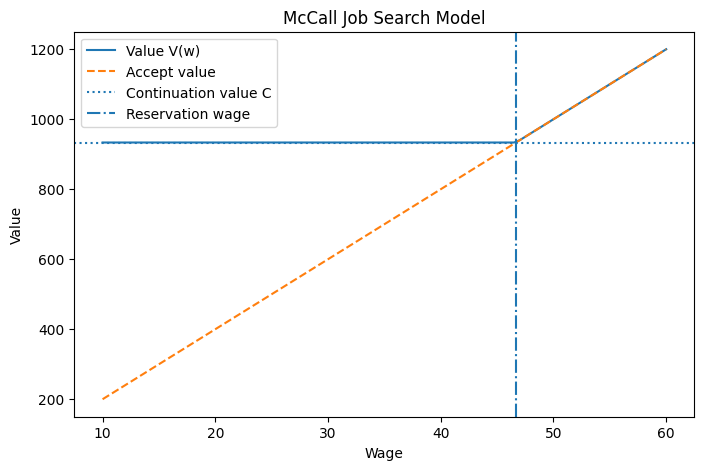

In [4]:
accept_value = w / (1 - beta)

plt.figure(figsize=(8, 5))
plt.plot(w, V, label="Value V(w)")
plt.plot(w, accept_value, linestyle="--", label="Accept value")
plt.axhline(C, linestyle=":", label="Continuation value C")
plt.axvline(reservation_wage, linestyle="-.", label="Reservation wage")
plt.xlabel("Wage")
plt.ylabel("Value")
plt.title("McCall Job Search Model")
plt.legend()
plt.show()

The kink occurs at the stopping boundary. Below the reservation wage, $V(w)=C$: the worker rejects and the current wage has no effect on value. Above it, $V(w)=w/(1-\beta)$: the worker accepts and value rises linearly with the wage.

# Problem 4. The Value of Waiting

### 4(a) Higher unemployment compensation

Higher $c$ raises the payoff from rejecting an offer. Therefore $C$ rises and the reservation wage rises. The worker can afford to be more selective.

### 4(b) Greater patience

A larger $\beta$ raises the value of future search opportunities relative to accepting a mediocre wage now. The worker becomes more selective, so the reservation wage generally rises.

### 4(c) Better wage-offer distribution

If high wages become more likely, rejecting today's offer becomes more valuable. The continuation value rises, and so does the reservation wage.

### 4(d) Connection to parking

When $p$ rises in the parking problem, good future opportunities are easier to find, so the driver waits until closer to the office.

The common principle is:

> **When future opportunities become more attractive, the option value of waiting rises, so the decision maker becomes more selective about stopping today.**

# Problem 5. Scalar Continuation-Value Iteration

### 5(a)

Since

$$
V(w)=\max\left\{\frac{w}{1-\beta},C\right\}
$$

and

$$
C=c+\beta E[V(W)],
$$

substitution gives

$$
\boxed{
C=c+\beta E\left[
\max\left\{\frac{W}{1-\beta},C\right\}
\right].
}
$$

In [5]:
C_scalar = 0.0

for it_scalar in range(100_000):
    C_new = c + beta * np.dot(
        prob,
        np.maximum(w / (1 - beta), C_scalar)
    )
    if abs(C_new - C_scalar) < tol:
        C_scalar = C_new
        break
    C_scalar = C_new

reservation_scalar = (1 - beta) * C_scalar

print(f"Scalar iterations: {it_scalar + 1}")
print(f"C from scalar iteration: {C_scalar:.10f}")
print(f"Reservation wage: {reservation_scalar:.10f}")
print(f"Difference from VFI C: {abs(C_scalar - C):.3e}")

Scalar iterations: 77
C from scalar iteration: 933.4690553744
Reservation wage: 46.6734527687
Difference from VFI C: 5.173e-11


The two procedures produce the same fixed point (up to numerical tolerance).

The scalar method is computationally simpler because rejection has the same value for every current wage. That special structure lets us summarize the continuation side of the Bellman equation with one number, $C$, rather than iterating on the entire vector $V(w)$.

# Problem 6. Job Separation

Let $U$ be the value of entering a period unemployed before receiving a wage offer, and $E(w)$ the value of employment at wage $w$.

### 6(a) Employment value

If a job ends with probability $\delta$,

$$
E(w)
=
w+\beta\left[(1-\delta)E(w)+\delta U\right].
$$

Solving,

$$
\boxed{
E(w)
=
\frac{w+\beta\delta U}
     {1-\beta(1-\delta)}.
}
$$

### 6(b) Unemployment equations

After observing wage $w$, the worker chooses between employment and rejection:

$$
\boxed{V(w)=\max\{E(w),U\}.}
$$

Before the next offer is observed,

$$
\boxed{
U=c+\beta E[V(W')].
}
$$

Together these equations define the modified search problem.

### 6(c) Reservation wage

Yes. $E(w)$ is increasing in $w$, while $U$ does not depend on the current wage. Hence there is still a cutoff satisfying

$$
E(\bar w)=U.
$$

Using the expression for $E(w)$,

$$
U
=
\frac{\bar w+\beta\delta U}
     {1-\beta(1-\delta)}.
$$

This simplifies to

$$
\boxed{\bar w=(1-\beta)U}.
$$

The numerical value of $U$, and therefore the reservation wage, changes with $\delta$.

### 6(d) Higher separation probability

A higher $\delta$ makes an accepted job less durable and therefore reduces the value of accepting a given wage relative to secure employment. In the full fixed point it also changes the unemployment value. The usual comparative-static implication in this model is a lower reservation wage: when jobs are less durable, the gain from waiting for a particularly high wage is less valuable, so the worker is willing to accept a lower current offer.

# Final Question: What Did the Parking Problem Teach Us?

Both models are optimal-stopping problems. The decision maker repeatedly compares the payoff from **stopping now** with the expected value of **continuing**. In the parking problem, stopping means taking the current space; in McCall, it means accepting the current wage.

The important lesson is that discounting is not what makes a problem dynamic. The parking problem contains no explicit discount factor, yet it has a Bellman equation because today's decision changes the state and determines which opportunities remain available. McCall adds discounting because payoffs occur over time and the worker is impatient, but the underlying dynamic-programming logic is the same.

> **Dynamic programming is fundamentally about recursive decision making, not about the presence of a discount factor.**